# Shortcut Models：从局部速度到少步生成

本实验把 Shortcut Models 的核心机制拆成三个可以独立检查的部分：

1. 用解析线性 ODE 验证 **两个半步可以合成一个整步 Shortcut**；
2. 在二维八高斯上训练普通 Flow Matching（FM）和 Shortcut 模型；
3. 比较 1、2、4、8、32 次函数调用（NFE）下的生成分布、Sliced Wasserstein Distance（SWD）和模式覆盖。

代码全部位于本 notebook。实验输出保存在 `shortcut_outputs/`。


## 1. 数学定义

设状态满足 ODE

$$
\frac{d x_t}{dt}=v(x_t,t).
$$

Shortcut 网络 $s_\theta(x_t,t,d)$ 预测区间 $[t,t+d]$ 上的**平均速度**，因此一步更新为

$$
x_{t+d}=x_t+d\,s_\theta(x_t,t,d).
$$

当 $d$ 很小时，它应退化为局部速度；当 $d=1$ 时，可以直接从 $t=0$ 一步到 $t=1$。把长度为 $d$ 的区间拆成两个半步，令

$$
v_1=s_{\bar\theta}(x_t,t,d/2),\qquad
x_{t+d/2}=x_t+\frac d2v_1,
$$

$$
v_2=s_{\bar\theta}(x_{t+d/2},t+d/2,d/2),
$$

则整步平均速度满足自举关系

$$
s_\theta(x_t,t,d)\approx \operatorname{sg}\!\left(\frac{v_1+v_2}{2}\right),
$$

其中 $\operatorname{sg}$ 表示停止梯度，$\bar\theta$ 是 EMA 参数。训练仍需最小步长上的 FM 监督作为锚点；单独满足自一致性并不能确定正确的数据输运。


In [1]:
import copy
import json
import math
import random
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = Path("shortcut_outputs")
OUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
print("device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)


device: cuda
GPU: NVIDIA GeForce GTX 1050 Ti


## 2. 解析检查：Shortcut 恒等式

考虑线性系统 $\dot x=Ax$。精确流映射为 $x_{t+d}=e^{Ad}x_t$，所以长度为 $d$ 的精确平均速度是

$$
s^*(x,t,d)=\frac{e^{Ad}-I}{d}x.
$$

下面直接计算一个整步速度和两个半步速度的合成误差。这个实验没有神经网络误差，可以单独验证 Shortcut 目标公式。


d=0.10 | identity max error=1.332e-14 | one-step Euler MSE=0.000404
d=0.25 | identity max error=1.243e-14 | one-step Euler MSE=0.016087
d=0.50 | identity max error=1.776e-15 | one-step Euler MSE=0.259500
d=1.00 | identity max error=1.776e-15 | one-step Euler MSE=3.858458


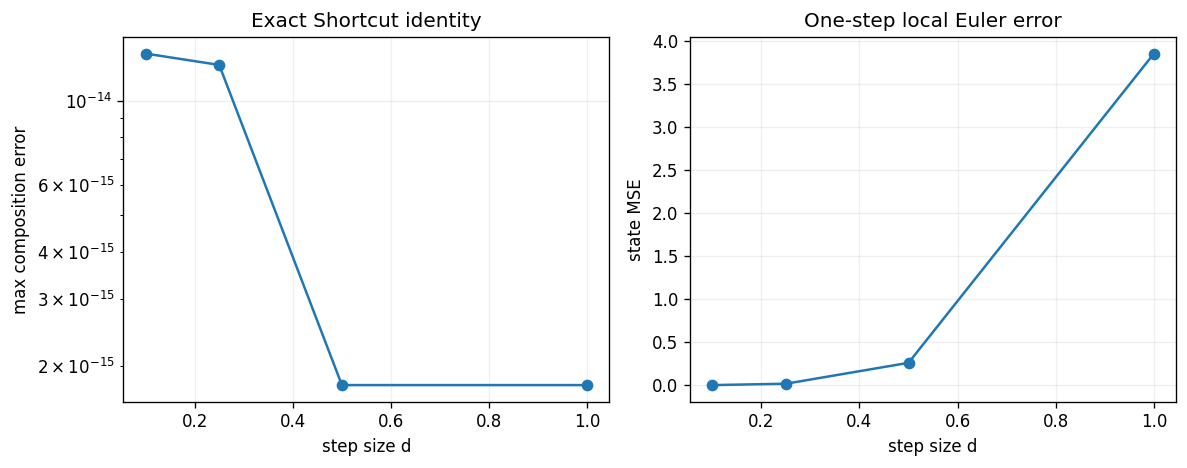

In [2]:
# 解析验证单独使用 float64，以观察接近机器精度的组合误差。
A = torch.tensor([[0.30, -2.00], [2.00, 0.30]], dtype=torch.float64, device=DEVICE)

def exact_flow(x, d):
    return x @ torch.matrix_exp(A * d).T

def exact_shortcut(x, d):
    if abs(float(d)) < 1e-12:
        return x @ A.T
    return (exact_flow(x, d) - x) / d

x = torch.randn(2048, 2, dtype=torch.float64, device=DEVICE)
ds = [0.1, 0.25, 0.5, 1.0]
identity_errors, euler_errors = [], []
for d in ds:
    v_full = exact_shortcut(x, d)
    v1 = exact_shortcut(x, d / 2)
    x_mid = x + (d / 2) * v1
    v2 = exact_shortcut(x_mid, d / 2)
    identity_errors.append((v_full - (v1 + v2) / 2).abs().max().item())

    x_exact = exact_flow(x, d)
    x_euler = x + d * exact_shortcut(x, 0.0)
    euler_errors.append((x_euler - x_exact).square().mean().item())
    print(f"d={d:.2f} | identity max error={identity_errors[-1]:.3e} | "
          f"one-step Euler MSE={euler_errors[-1]:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].semilogy(ds, identity_errors, "o-")
axes[0].set(xlabel="step size d", ylabel="max composition error", title="Exact Shortcut identity")
axes[1].plot(ds, euler_errors, "o-")
axes[1].set(xlabel="step size d", ylabel="state MSE", title="One-step local Euler error")
fig.tight_layout()
fig.savefig(OUT_DIR / "01_exact_composition.png", bbox_inches="tight")
plt.show()


## 3. 二维八高斯任务

源分布为 $p_0=\mathcal N(0,I_2)$。目标分布由半径为 4 的圆周上八个等权高斯组成，每个分量的标准差为 0.3。训练配对独立采样 $x_0\sim p_0$ 与 $x_1\sim p_1$，使用线性条件概率路径

$$
x_t=(1-t)x_0+t x_1,\qquad u_t=x_1-x_0.
$$

这是**无类别条件**的生成实验，网络不会看到高斯分量编号。


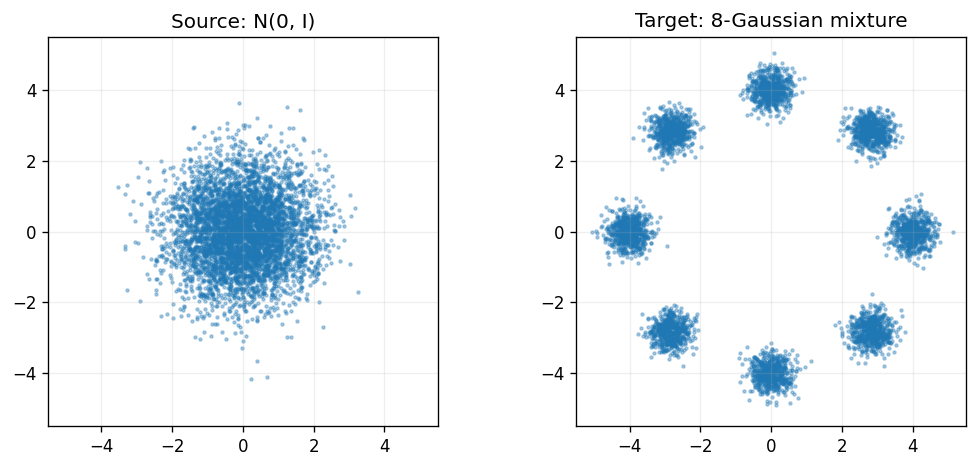

In [3]:
RADIUS, DATA_STD, NUM_MODES = 4.0, 0.30, 8
angles = 2 * math.pi * torch.arange(NUM_MODES, device=DEVICE) / NUM_MODES
CENTERS = RADIUS * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)

def sample_data(n):
    idx = torch.randint(NUM_MODES, (n,), device=DEVICE)
    return CENTERS[idx] + DATA_STD * torch.randn(n, 2, device=DEVICE)

def sample_noise(n):
    return torch.randn(n, 2, device=DEVICE)

with torch.no_grad():
    source, target = sample_noise(5000), sample_data(5000)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, pts, title in zip(axes, [source, target], ["Source: N(0, I)", "Target: 8-Gaussian mixture"]):
    q = pts.cpu().numpy()
    ax.scatter(q[:, 0], q[:, 1], s=3, alpha=0.35)
    ax.set(title=title, xlim=(-5.5, 5.5), ylim=(-5.5, 5.5), aspect="equal")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_source_target.png", bbox_inches="tight")
plt.show()


## 4. 网络、时间步编码与 EMA

模型接收 $(x_t,t,d)$。$t$ 表示当前位置，$d$ 表示希望跨越的区间长度。普通 FM 和最细粒度 Shortcut 都在 $d_{\min}=1/M$ 上接受真实 FM 监督；更大的 $d$ 由两个 $d/2$ 预测自举。

这里保留最小正步长作为 FM 锚点。若把锚点编码成 $d=0$，却在第一次自举时查询从未训练的 $d=1/M$，会人为制造训练断层。


In [4]:
@dataclass
class Config:
    seed: int = 42
    batch_size: int = 512
    steps: int = 6000
    lr: float = 1e-3
    hidden_dim: int = 128
    depth: int = 3
    M: int = 32
    bootstrap_ratio: float = 0.25
    ema_decay: float = 0.999
    use_ema_target: bool = True
    weight_decay: float = 0.1
    discrete_time: bool = True
    train_type: str = "shortcut"  # fm / shortcut / sc_only
    log_interval: int = 1000
    track_drift: bool = False
    drift_interval: int = 100

class FourierTimeEmbedding(nn.Module):
    def __init__(self, num_freqs=8):
        super().__init__()
        self.register_buffer("freqs", 2.0 ** torch.arange(num_freqs))

    def forward(self, z):
        a = 2 * math.pi * z * self.freqs
        return torch.cat([z, torch.sin(a), torch.cos(a)], dim=-1)

class ShortcutNet(nn.Module):
    def __init__(self, hidden_dim=128, depth=3):
        super().__init__()
        self.embed = FourierTimeEmbedding(8)
        layers, width = [], 2 + 17 + 17
        for _ in range(depth):
            layers += [nn.Linear(width, hidden_dim), nn.SiLU()]
            width = hidden_dim
        layers.append(nn.Linear(width, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x, t, d):
        return self.net(torch.cat([x, self.embed(t), self.embed(d)], dim=-1))

@torch.no_grad()
def update_ema(ema_model, model, decay):
    for p_ema, p in zip(ema_model.parameters(), model.parameters()):
        p_ema.lerp_(p, 1 - decay)
    for b_ema, b in zip(ema_model.buffers(), model.buffers()):
        b_ema.copy_(b)


## 5. 两类训练目标

每个 batch 混合两种样本：

- **FM 锚点**：输入 $d=1/M$，监督目标为 $x_1-x_0$；
- **Bootstrap 样本**：从 $d\in\{2/M,4/M,\ldots,1\}$ 中采样，用 EMA 网络的两个半步组成整步目标。

目标分支全部在 `torch.no_grad()` 下计算。在线网络反向传播后，再更新 EMA 网络。


In [5]:
def make_fm_batch(n, M):
    x0, x1 = sample_noise(n), sample_data(n)
    j = torch.randint(M, (n, 1), device=DEVICE)
    t = j.float() / M
    d = torch.full_like(t, 1.0 / M)
    xt = (1 - t) * x0 + t * x1
    return xt, t, d, x1 - x0

def sample_bootstrap_times(n, M, discrete=True):
    assert M >= 2 and M & (M - 1) == 0
    # d = 2/M, 4/M, ..., 1；其半步包含最小锚点 1/M。
    level = torch.randint(int(math.log2(M)), (n, 1), device=DEVICE)
    d = (2.0 ** (level + 1).float()) / M
    if discrete:
        sections = torch.round(1.0 / d).long()
        j = torch.floor(torch.rand(n, 1, device=DEVICE) * sections).long()
        t = j.float() * d
    else:
        t = torch.rand(n, 1, device=DEVICE) * (1 - d)
    return t, d

@torch.no_grad()
def compute_fixed_targets(model, x, t, d):
    half = d / 2
    v1 = model(x, t, half)
    v2 = model(x + half * v1, t + half, half)
    return (v1 + v2) / 2

@torch.no_grad()
def make_bootstrap_batch(target_model, n, M, discrete_time=True):
    x0, x1 = sample_noise(n), sample_data(n)
    t, d = sample_bootstrap_times(n, M, discrete_time)
    xt = (1 - t) * x0 + t * x1
    target = compute_fixed_targets(target_model, xt, t, d)
    return xt, t, d, target

def compute_loss(model, ema_model, cfg):
    if cfg.train_type == "fm":
        n_boot = 0
    elif cfg.train_type == "sc_only":
        n_boot = cfg.batch_size
    else:
        n_boot = int(cfg.batch_size * cfg.bootstrap_ratio)
    n_fm = cfg.batch_size - n_boot

    batches = []
    if n_boot:
        target_model = ema_model if cfg.use_ema_target else model
        batches.append(make_bootstrap_batch(target_model, n_boot, cfg.M, cfg.discrete_time))
    if n_fm:
        batches.append(make_fm_batch(n_fm, cfg.M))

    x = torch.cat([b[0] for b in batches])
    t = torch.cat([b[1] for b in batches])
    d = torch.cat([b[2] for b in batches])
    y = torch.cat([b[3] for b in batches])
    error = (model(x, t, d) - y.detach()).square().mean(dim=1)
    if n_boot == 0:
        loss_fm, loss_sc = error.mean(), error.new_zeros(())
    elif n_fm == 0:
        loss_fm, loss_sc = error.new_zeros(()), error.mean()
    else:
        loss_sc, loss_fm = error[:n_boot].mean(), error[n_boot:].mean()
    return error.mean(), loss_fm.detach(), loss_sc.detach()


In [6]:
def train_model(cfg):
    set_seed(cfg.seed)
    model = ShortcutNet(cfg.hidden_dim, cfg.depth).to(DEVICE)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    history = {"loss": [], "fm": [], "bootstrap": [],
               "drift_step": [], "online_drift": [], "ema_drift": []}

    if cfg.track_drift:
        with torch.no_grad():
            px0, px1 = sample_noise(512), sample_data(512)
            pt, pd = sample_bootstrap_times(512, cfg.M, cfg.discrete_time)
            px = (1 - pt) * px0 + pt * px1
            prev_online = compute_fixed_targets(model, px, pt, pd)
            prev_ema = compute_fixed_targets(ema, px, pt, pd)

    for step in range(1, cfg.steps + 1):
        model.train()
        loss, loss_fm, loss_sc = compute_loss(model, ema, cfg)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        update_ema(ema, model, cfg.ema_decay)
        history["loss"].append(loss.item())
        history["fm"].append(loss_fm.item())
        history["bootstrap"].append(loss_sc.item())

        if cfg.track_drift and step % cfg.drift_interval == 0:
            with torch.no_grad():
                now_online = compute_fixed_targets(model, px, pt, pd)
                now_ema = compute_fixed_targets(ema, px, pt, pd)
                history["drift_step"].append(step)
                history["online_drift"].append((now_online - prev_online).square().mean().item())
                history["ema_drift"].append((now_ema - prev_ema).square().mean().item())
                prev_online, prev_ema = now_online, now_ema

        if step % cfg.log_interval == 0:
            print(f"{cfg.train_type:8s} step={step:4d} loss={loss.item():.4f} "
                  f"FM={loss_fm.item():.4f} bootstrap={loss_sc.item():.4f}")
    return model.eval(), ema.eval(), history

cfg_fm = Config(train_type="fm")
cfg_sc = Config(train_type="shortcut", bootstrap_ratio=0.25, track_drift=True)
print("Training the FM baseline...")
fm_model, fm_ema, fm_history = train_model(cfg_fm)
print("\nTraining the Shortcut model...")
sc_model, sc_ema, sc_history = train_model(cfg_sc)


Training the FM baseline...


fm       step=1000 loss=3.9573 FM=3.9573 bootstrap=0.0000


fm       step=2000 loss=4.1181 FM=4.1181 bootstrap=0.0000


fm       step=3000 loss=4.2951 FM=4.2951 bootstrap=0.0000


fm       step=4000 loss=3.9307 FM=3.9307 bootstrap=0.0000


...

shortcut step=2000 loss=3.0357 FM=4.0410 bootstrap=0.0196


shortcut step=3000 loss=3.0454 FM=4.0553 bootstrap=0.0158


shortcut step=4000 loss=2.8947 FM=3.8544 bootstrap=0.0158


shortcut step=5000 loss=3.1301 FM=4.1666 bootstrap=0.0204


shortcut step=6000 loss=3.1461 FM=4.1863 bootstrap=0.0256


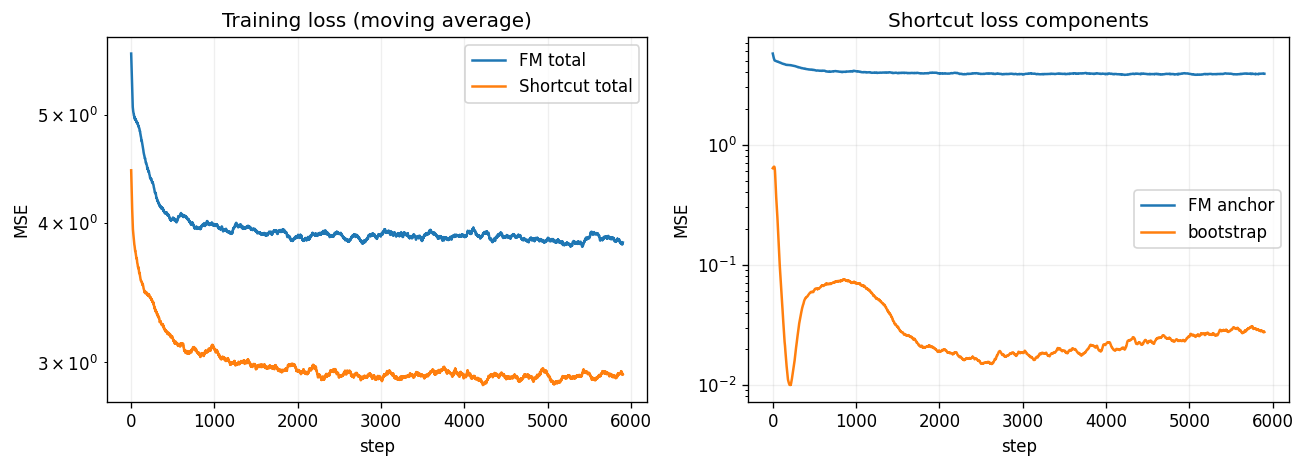

In [7]:
def smooth_curve(values, window=100):
    v = np.asarray(values)
    if len(v) < window:
        return v
    return np.convolve(v, np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(smooth_curve(fm_history["loss"]), label="FM total")
axes[0].plot(smooth_curve(sc_history["loss"]), label="Shortcut total")
axes[0].set(title="Training loss (moving average)", xlabel="step", ylabel="MSE", yscale="log")
axes[0].legend()
axes[1].plot(smooth_curve(sc_history["fm"]), label="FM anchor")
axes[1].plot(smooth_curve(sc_history["bootstrap"]), label="bootstrap")
axes[1].set(title="Shortcut loss components", xlabel="step", ylabel="MSE", yscale="log")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "03_training_curves.png", bbox_inches="tight")
plt.show()


## 6. 采样与评价

FM 基线始终查询最小步长编码 $d=1/M$，再用 Euler 积分。Shortcut 采样在 NFE 为 $K$ 时直接查询 $d=1/K$：

$$
x_{(i+1)/K}=x_{i/K}+\frac1K s_\theta(x_{i/K},i/K,1/K).
$$

评价包含：

- **SWD**：多个随机一维投影上的 Wasserstein 距离，越小越好；
- **Mode TV**：生成样本分配到最近模式后，其频率与均匀分布的总变差距离，越小越好；
- **Nearest RMSE**：样本到最近峰中心的均方根距离；目标分布的理论量级约为 $\sqrt2\times0.3\approx0.424$。


In [8]:
@torch.no_grad()
def sample_model(model, x0, nfe, M, shortcut):
    x = x0.clone()
    dt = 1.0 / nfe
    for i in range(nfe):
        t = torch.full((len(x), 1), i * dt, device=DEVICE)
        d_value = dt if shortcut else 1.0 / M
        d = torch.full_like(t, d_value)
        x.add_(dt * model(x, t, d))
    return x

@torch.no_grad()
def sliced_wasserstein(x, y, n_proj=256):
    directions = F.normalize(torch.randn(n_proj, 2, device=DEVICE), dim=1)
    px, py = torch.sort(x @ directions.T, dim=0).values, torch.sort(y @ directions.T, dim=0).values
    return (px - py).abs().mean().item()

@torch.no_grad()
def distribution_metrics(x, target):
    nearest = torch.cdist(x, CENTERS).min(dim=1)
    counts = torch.bincount(nearest.indices, minlength=NUM_MODES).float() / len(x)
    return {
        "swd": sliced_wasserstein(x, target),
        "mode_tv": (counts - 1 / NUM_MODES).abs().sum().div(2).item(),
        "nearest_rmse": nearest.values.square().mean().sqrt().item(),
        "mode_frequencies": counts.cpu().tolist(),
    }

set_seed(2026)
n_eval = 4096
x0_eval, target_eval = sample_noise(n_eval), sample_data(n_eval)
nfes = [1, 2, 4, 8, 32]
all_samples, metrics = {}, {"FM": {}, "Shortcut": {}}
for name, model, is_shortcut in [("FM", fm_ema, False), ("Shortcut", sc_ema, True)]:
    for nfe in nfes:
        generated = sample_model(model, x0_eval, nfe, cfg_sc.M, is_shortcut)
        all_samples[(name, nfe)] = generated
        metrics[name][str(nfe)] = distribution_metrics(generated, target_eval)

metrics["target_reference"] = distribution_metrics(target_eval, sample_data(n_eval))
print(json.dumps(metrics, indent=2))


{
  "FM": {
    "1": {
      "swd": 2.427928924560547,
      "mode_tv": 0.2294921875,
      "nearest_rmse": 3.803373336791992,
      "mode_frequencies": [
        0.048095703125,
        0.103515625,
        0.059326171875,
        0.072509765625,
        0.112060546875,
        0.24169921875,
        0.192626953125,
        0.170166015625
      ]
    },
    "2": {
      "swd": 0.676307737827301,
      "mode_tv": 0.025390625,
      "nearest_rmse": 1.4947025775909424,
      "mode_frequencies": [
        0.1259765625,
        0.119873046875,
        0.11767578125,
        0.1181640625,
        0.121826171875,
        0.14794921875,
        0.12646484375,
        0.1220703125
      ]
    },
    "4": {
      "swd": 0.26298511028289795,
      "mode_tv": 0.017333984375,
      "nearest_rmse": 0.7538406252861023,
      "mode_frequencies": [
        0.12939453125,
        0.121337890625,
        0.119140625,
        0.121337890625,
        0.127197265625,
        0.13427734375,
        0.120849

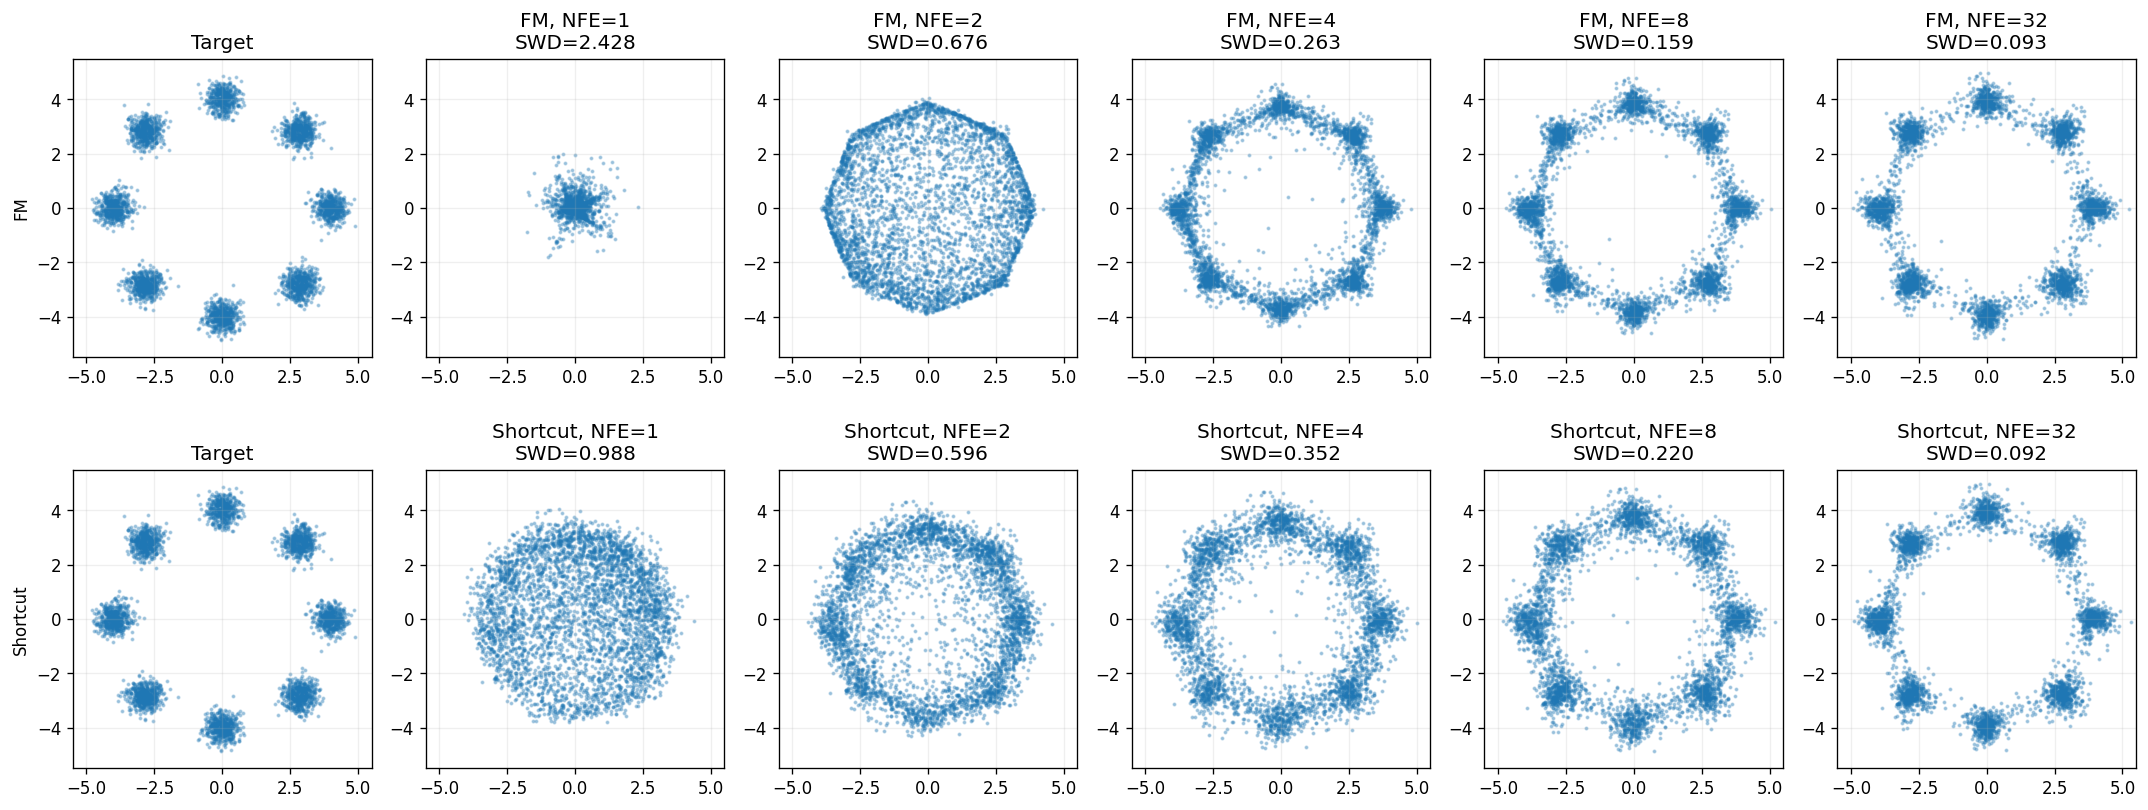

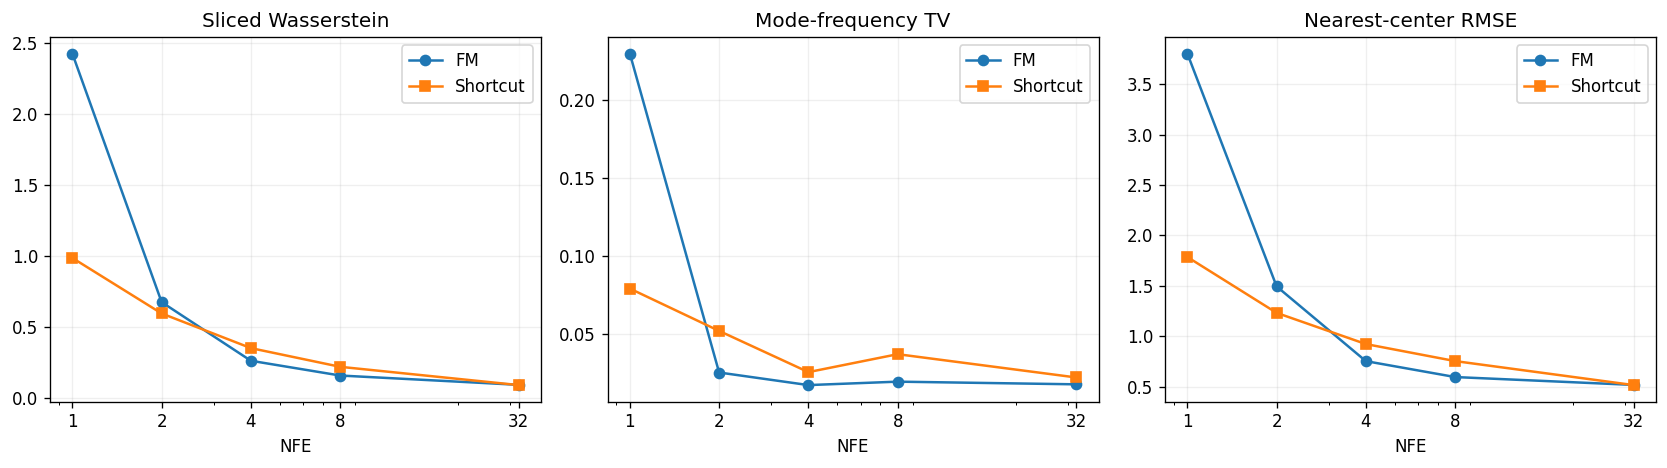

In [9]:
fig, axes = plt.subplots(2, len(nfes) + 1, figsize=(18, 7))
for row, name in enumerate(["FM", "Shortcut"]):
    q = target_eval.cpu().numpy()
    axes[row, 0].scatter(q[:, 0], q[:, 1], s=2, alpha=0.3)
    axes[row, 0].set_title("Target")
    for col, nfe in enumerate(nfes, 1):
        q = all_samples[(name, nfe)].cpu().numpy()
        axes[row, col].scatter(q[:, 0], q[:, 1], s=2, alpha=0.3)
        m = metrics[name][str(nfe)]
        axes[row, col].set_title(f"{name}, NFE={nfe}\nSWD={m['swd']:.3f}")
    axes[row, 0].set_ylabel(name)
    for ax in axes[row]:
        ax.set(xlim=(-5.5, 5.5), ylim=(-5.5, 5.5), aspect="equal")
fig.tight_layout()
fig.savefig(OUT_DIR / "04_samples_all_nfe.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name, marker in [("FM", "o"), ("Shortcut", "s")]:
    axes[0].plot(nfes, [metrics[name][str(k)]["swd"] for k in nfes], marker=marker, label=name)
    axes[1].plot(nfes, [metrics[name][str(k)]["mode_tv"] for k in nfes], marker=marker, label=name)
    axes[2].plot(nfes, [metrics[name][str(k)]["nearest_rmse"] for k in nfes], marker=marker, label=name)
for ax, title in zip(axes, ["Sliced Wasserstein", "Mode-frequency TV", "Nearest-center RMSE"]):
    ax.set(xlabel="NFE", title=title, xscale="log")
    ax.set_xticks(nfes, nfes)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "05_metrics_vs_nfe.png", bbox_inches="tight")
plt.show()


## 7. 自一致性诊断

下面直接测量模型的一步预测和两个半步组合之间的均方误差。它用于检查模型是否学会 Shortcut 递归关系。该值只衡量内部一致性；必须结合 SWD 和生成图判断输运是否正确。


In [10]:
@torch.no_grad()
def consistency_error(model, n=4096, M=32):
    x0, x1 = sample_noise(n), sample_data(n)
    t, d = sample_bootstrap_times(n, M)
    x = (1 - t) * x0 + t * x1
    full = model(x, t, d)
    half = d / 2
    v1 = model(x, t, half)
    v2 = model(x + half * v1, t + half, half)
    return (full - (v1 + v2) / 2).square().mean().item()

metrics["consistency_mse"] = {
    "FM": consistency_error(fm_ema, M=cfg_fm.M),
    "Shortcut": consistency_error(sc_ema, M=cfg_sc.M),
}
metrics["config"] = {"FM": asdict(cfg_fm), "Shortcut": asdict(cfg_sc)}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Consistency MSE:", metrics["consistency_mse"])
print("Saved:", OUT_DIR / "metrics.json")


Consistency MSE: {'FM': 0.984040379524231, 'Shortcut': 0.09442687034606934}
Saved: shortcut_outputs/metrics.json


## 8. 主实验阶段结论

前面的实验覆盖了解析恒等式和 FM/Shortcut 主对比。下面继续执行方案中的 C–F 消融，分别检查 EMA、Bootstrap 比例、Weight Decay、时间采样和纯自一致性训练。最终结论以全部消融运行后的统一表格为准。


## 9. 统一消融评价函数

所有消融均使用相同随机评价样本，并统一报告 1、4、32 步 SWD 与流映射组合误差。除被研究变量外，其余配置保持与主实验一致。


In [11]:
@torch.no_grad()
def evaluate_selected(model, shortcut=True, seed=2027):
    set_seed(seed)
    x0, target = sample_noise(4096), sample_data(4096)
    out = {}
    for nfe in [1, 4, 32]:
        generated = sample_model(model, x0, nfe, cfg_sc.M, shortcut)
        out[str(nfe)] = distribution_metrics(generated, target)
    out["consistency_mse"] = consistency_error(model, M=cfg_sc.M)
    return out

def train_evaluate_release(cfg, shortcut=True):
    model, ema, history = train_model(cfg)
    result = evaluate_selected(ema, shortcut=shortcut)
    model.cpu(); ema.cpu()
    del model, ema
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, history

ablation_results = {}


## 10. 实验 C：EMA Target 与推理 EMA

- C1：在线模型构造 Bootstrap Target，在线模型推理；
- C2：在线模型构造 Bootstrap Target，EMA 模型推理；
- C3：EMA 模型构造 Bootstrap Target，EMA 模型推理。

同时在固定 probe batch 上每 100 步测量一次在线网络和 EMA 网络所产生 Target 的漂移。


Training C1/C2: online bootstrap target...


shortcut step=1000 loss=3.0572 FM=4.0570 bootstrap=0.0578


shortcut step=2000 loss=3.0423 FM=4.0437 bootstrap=0.0382


shortcut step=3000 loss=3.0436 FM=4.0476 bootstrap=0.0318


shortcut step=4000 loss=2.8894 FM=3.8446 bootstrap=0.0238


shortcut step=5000 loss=3.1378 FM=4.1781 bootstrap=0.0169


shortcut step=6000 loss=3.1529 FM=4.1959 bootstrap=0.0239


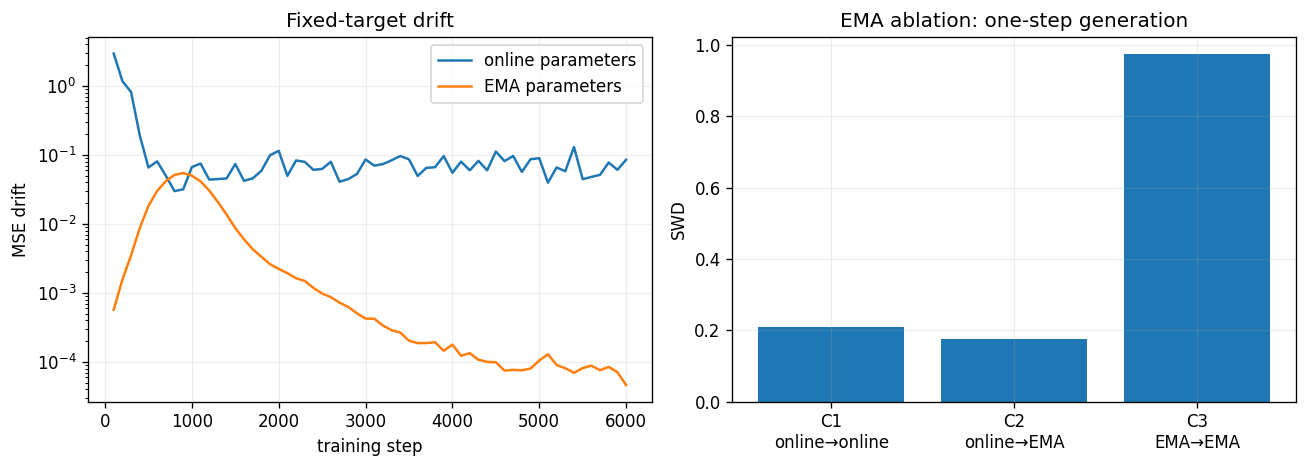

{
  "C1_online_target_online_eval": {
    "1": {
      "swd": 0.2106567919254303,
      "mode_tv": 0.05029296875,
      "nearest_rmse": 0.8225871920585632,
      "mode_frequencies": [
        0.10302734375,
        0.11962890625,
        0.121826171875,
        0.12744140625,
        0.137451171875,
        0.13330078125,
        0.105224609375,
        0.152099609375
      ]
    },
    "4": {
      "swd": 0.1442430317401886,
      "mode_tv": 0.0556640625,
      "nearest_rmse": 0.5367051362991333,
      "mode_frequencies": [
        0.106689453125,
        0.11767578125,
        0.117431640625,
        0.1328125,
        0.146484375,
        0.11962890625,
        0.10791015625,
        0.1513671875
      ]
    },
    "32": {
      "swd": 0.1349782645702362,
      "mode_tv": 0.05322265625,
      "nearest_rmse": 0.5002533793449402,
      "mode_frequencies": [
        0.114990234375,
        0.121337890625,
        0.108642578125,
        0.143798828125,
        0.14599609375,
        0.

In [12]:
cfg_online_target = Config(train_type="shortcut", use_ema_target=False, track_drift=True)
print("Training C1/C2: online bootstrap target...")
online_model, online_ema, online_history = train_model(cfg_online_target)

ema_results = {
    "C1_online_target_online_eval": evaluate_selected(online_model, shortcut=True),
    "C2_online_target_ema_eval": evaluate_selected(online_ema, shortcut=True),
    "C3_ema_target_ema_eval": evaluate_selected(sc_ema, shortcut=True),
}
ablation_results["ema"] = ema_results

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(online_history["drift_step"], online_history["online_drift"], label="online parameters")
axes[0].plot(online_history["drift_step"], online_history["ema_drift"], label="EMA parameters")
axes[0].set(title="Fixed-target drift", xlabel="training step", ylabel="MSE drift", yscale="log")
axes[0].legend()
names = ["C1\nonline→online", "C2\nonline→EMA", "C3\nEMA→EMA"]
axes[1].bar(names, [ema_results[k]["1"]["swd"] for k in ema_results])
axes[1].set(title="EMA ablation: one-step generation", ylabel="SWD")
fig.tight_layout()
fig.savefig(OUT_DIR / "06_ema_and_target_drift.png", bbox_inches="tight")
plt.show()
print(json.dumps(ema_results, indent=2))

online_model.cpu(); online_ema.cpu()
del online_model, online_ema
if torch.cuda.is_available(): torch.cuda.empty_cache()


## 11. 实验 D：Bootstrap 比例

比较 $\rho\in\{0,0.125,0.25,0.5,0.75\}$。$\rho=0$ 复用 FM 基线，$\rho=0.25$ 复用主 Shortcut 模型，其余配置重新训练。



Training bootstrap_ratio=0.125...


shortcut step=1000 loss=3.4771 FM=3.9535 bootstrap=0.1425


shortcut step=2000 loss=3.6341 FM=4.1469 bootstrap=0.0450


shortcut step=3000 loss=3.2866 FM=3.7516 bootstrap=0.0312


shortcut step=4000 loss=3.4414 FM=3.9294 bootstrap=0.0252


...

shortcut step=2000 loss=1.0324 FM=4.1123 bootstrap=0.0057


shortcut step=3000 loss=0.9074 FM=3.6105 bootstrap=0.0064


shortcut step=4000 loss=1.1636 FM=4.6330 bootstrap=0.0071


shortcut step=5000 loss=0.8870 FM=3.5274 bootstrap=0.0068


shortcut step=6000 loss=1.0766 FM=4.2715 bootstrap=0.0116


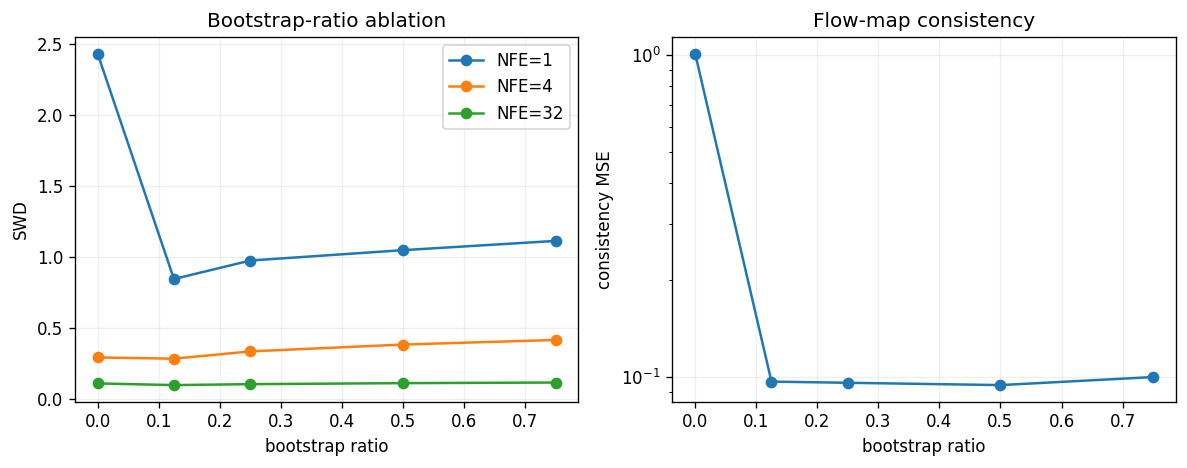

In [13]:
ratio_results = {
    "0.0": evaluate_selected(fm_ema, shortcut=False),
    "0.25": evaluate_selected(sc_ema, shortcut=True),
}
for ratio in [0.125, 0.5, 0.75]:
    print(f"\nTraining bootstrap_ratio={ratio}...")
    cfg = Config(train_type="shortcut", bootstrap_ratio=ratio)
    ratio_results[str(ratio)], _ = train_evaluate_release(cfg, shortcut=True)
ablation_results["bootstrap_ratio"] = ratio_results

ratios = [0.0, 0.125, 0.25, 0.5, 0.75]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for nfe in [1, 4, 32]:
    axes[0].plot(ratios, [ratio_results[str(r)][str(nfe)]["swd"] for r in ratios], "o-", label=f"NFE={nfe}")
axes[0].set(title="Bootstrap-ratio ablation", xlabel="bootstrap ratio", ylabel="SWD")
axes[0].legend()
axes[1].plot(ratios, [ratio_results[str(r)]["consistency_mse"] for r in ratios], "o-")
axes[1].set(title="Flow-map consistency", xlabel="bootstrap ratio", ylabel="consistency MSE", yscale="log")
fig.tight_layout()
fig.savefig(OUT_DIR / "07_bootstrap_ratio_ablation.png", bbox_inches="tight")
plt.show()


## 12. 实验 E：Weight Decay 与时间采样

Weight Decay 比较 $\{0,0.01,0.1,0.3\}$。时间采样比较与推理网格一致的离散 $t$ 和 $t\sim U(0,1-d)$ 的连续采样。



Training weight_decay=0.0...


shortcut step=1000 loss=3.0538 FM=4.0524 bootstrap=0.0579


shortcut step=2000 loss=3.2145 FM=4.2783 bootstrap=0.0229


shortcut step=3000 loss=2.7791 FM=3.6993 bootstrap=0.0185


shortcut step=4000 loss=2.8939 FM=3.8524 bootstrap=0.0183


...

shortcut step=2000 loss=3.2302 FM=4.2993 bootstrap=0.0228


shortcut step=3000 loss=2.8083 FM=3.7377 bootstrap=0.0204


shortcut step=4000 loss=2.8946 FM=3.8531 bootstrap=0.0189


shortcut step=5000 loss=3.1651 FM=4.2147 bootstrap=0.0162


shortcut step=6000 loss=3.1116 FM=4.1412 bootstrap=0.0227


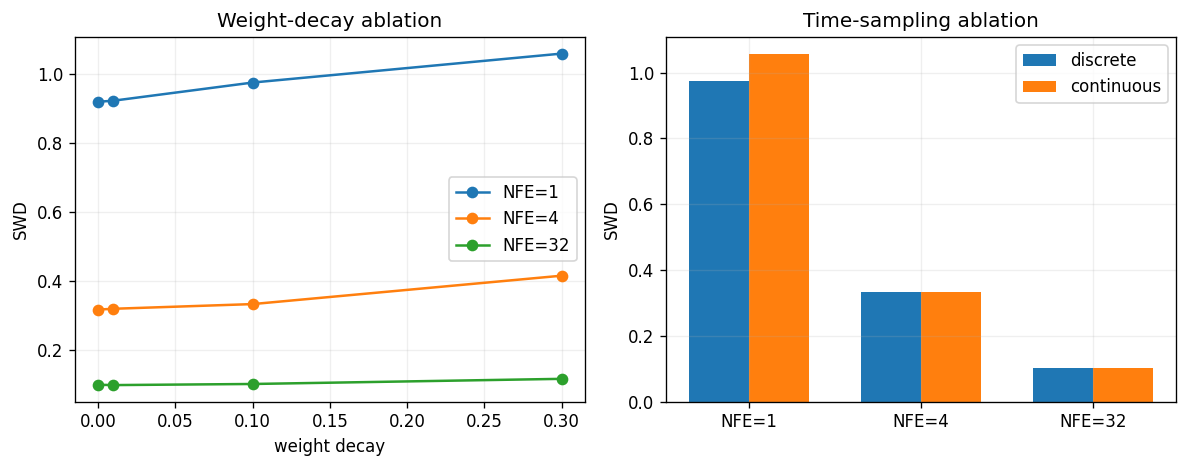

In [14]:
wd_results = {"0.1": evaluate_selected(sc_ema, shortcut=True)}
for wd in [0.0, 0.01, 0.3]:
    print(f"\nTraining weight_decay={wd}...")
    cfg = Config(train_type="shortcut", weight_decay=wd)
    wd_results[str(wd)], _ = train_evaluate_release(cfg, shortcut=True)

time_results = {"discrete": evaluate_selected(sc_ema, shortcut=True)}
print("\nTraining continuous-time bootstrap sampling...")
cfg_continuous = Config(train_type="shortcut", discrete_time=False)
time_results["continuous"], _ = train_evaluate_release(cfg_continuous, shortcut=True)
ablation_results["weight_decay"] = wd_results
ablation_results["time_sampling"] = time_results

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
wds = [0.0, 0.01, 0.1, 0.3]
for nfe in [1, 4, 32]:
    axes[0].plot(wds, [wd_results[str(w)][str(nfe)]["swd"] for w in wds], "o-", label=f"NFE={nfe}")
axes[0].set(title="Weight-decay ablation", xlabel="weight decay", ylabel="SWD")
axes[0].legend()
x = np.arange(3); width = 0.35
axes[1].bar(x-width/2, [time_results["discrete"][str(k)]["swd"] for k in [1,4,32]], width, label="discrete")
axes[1].bar(x+width/2, [time_results["continuous"][str(k)]["swd"] for k in [1,4,32]], width, label="continuous")
axes[1].set(title="Time-sampling ablation", ylabel="SWD", xticks=x, xticklabels=["NFE=1","NFE=4","NFE=32"])
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "08_weight_decay_time_ablation.png", bbox_inches="tight")
plt.show()


## 13. 实验 F：纯自一致性是否足够

比较 FM Only、SC Only、FM+SC。SC Only 没有任何真实速度监督，用它直接检验“低自一致性误差是否能够保证正确目标分布”。


Training SC-only model...


sc_only  step=1000 loss=0.0000 FM=0.0000 bootstrap=0.0000


sc_only  step=2000 loss=0.0000 FM=0.0000 bootstrap=0.0000


sc_only  step=3000 loss=0.0000 FM=0.0000 bootstrap=0.0000


sc_only  step=4000 loss=0.0000 FM=0.0000 bootstrap=0.0000


sc_only  step=5000 loss=0.0000 FM=0.0000 bootstrap=0.0000


sc_only  step=6000 loss=0.0000 FM=0.0000 bootstrap=0.0000


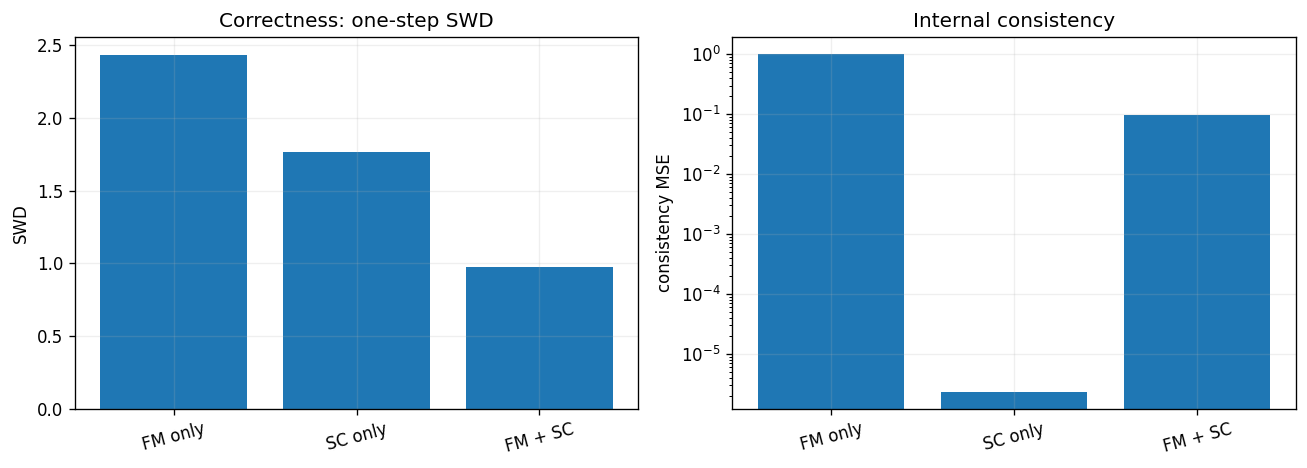


Unified ablation table
group              config                          SWD@1    SWD@4    SWD@32     Cons.
ema                C1_online_target_online_eval    0.211    0.144     0.135    0.0265
ema                C2_online_target_ema_eval       0.176    0.132     0.099    0.0243
ema                C3_ema_target_ema_eval          0.974    0.333     0.101    0.0961
bootstrap_ratio    0.0                             2.435    0.290     0.107    1.0111
bootstrap_ratio    0.25                            0.974    0.333     0.101    0.0961
bootstrap_ratio    0.125                           0.844    0.281     0.095    0.0969
bootstrap_ratio    0.5                             1.047    0.381     0.109    0.0945
bootstrap_ratio    0.75                            1.113    0.414     0.113    0.1001
weight_decay       0.1                             0.974    0.333     0.101    0.0961
weight_decay       0.0                             0.919    0.317     0.099    0.0920
weight_decay       0.01       

In [15]:
print("Training SC-only model...")
cfg_sc_only = Config(train_type="sc_only")
sc_only_result, sc_only_history = train_evaluate_release(cfg_sc_only, shortcut=True)
loss_component_results = {
    "FM_only": evaluate_selected(fm_ema, shortcut=False),
    "SC_only": sc_only_result,
    "FM_plus_SC": evaluate_selected(sc_ema, shortcut=True),
}
ablation_results["loss_components"] = loss_component_results

rows = []
for group, configs in ablation_results.items():
    for name, result in configs.items():
        rows.append({
            "group": group, "config": name,
            "SWD@1": result["1"]["swd"], "SWD@4": result["4"]["swd"],
            "SWD@32": result["32"]["swd"], "consistency": result["consistency_mse"],
        })

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["FM only", "SC only", "FM + SC"]
keys = ["FM_only", "SC_only", "FM_plus_SC"]
axes[0].bar(labels, [loss_component_results[k]["1"]["swd"] for k in keys])
axes[0].set(title="Correctness: one-step SWD", ylabel="SWD")
axes[1].bar(labels, [loss_component_results[k]["consistency_mse"] for k in keys])
axes[1].set(title="Internal consistency", ylabel="consistency MSE", yscale="log")
for ax in axes: ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(OUT_DIR / "09_sc_only_counterexample.png", bbox_inches="tight")
plt.show()

(OUT_DIR / "ablations.json").write_text(json.dumps(ablation_results, indent=2), encoding="utf-8")
print("\nUnified ablation table")
print(f"{'group':18s} {'config':28s} {'SWD@1':>8s} {'SWD@4':>8s} {'SWD@32':>9s} {'Cons.':>9s}")
for r in rows:
    print(f"{r['group']:18s} {r['config']:28s} {r['SWD@1']:8.3f} {r['SWD@4']:8.3f} "
          f"{r['SWD@32']:9.3f} {r['consistency']:9.4f}")


## 14. 逐项覆盖核对与实际结论

| 原方案内容 | Notebook 对应部分 | 状态 |
|---|---|---|
| 实验 A：解析 ODE、组合恒等式、一步 Euler 误差 | 第 2 节 | 已执行 |
| 实验 B：二维八高斯，FM 与 Shortcut | 第 3–6 节 | 已执行 |
| NFE 1/2/4/8/32 对比 | 第 6 节 | 已执行 |
| EMA Target、在线/EMA 推理拆分 | 第 10 节 C1/C2/C3 | 已执行 |
| 固定 probe 的 Target Drift | 第 10 节 | 已执行 |
| Bootstrap 比例 0/0.125/0.25/0.5/0.75 | 第 11 节 | 已执行 |
| Weight Decay 0/0.01/0.1/0.3 | 第 12 节 | 已执行 |
| 离散与连续时间采样 | 第 12 节 | 已执行 |
| FM Only / SC Only / FM+SC | 第 13 节 | 已执行 |
| 独立流映射组合误差 | 第 7、9–13 节 | 已执行 |
| 16×16 小型图像实验 | 原方案的下一阶段建议 | 本轮不包含 |

### 本次运行得到的结论

- **大步监督改善一步生成。** FM Only 的一步 SWD 为 `2.435`，FM+SC 为 `0.974`，但 6000 步的 EMA Target 主模型仍没有形成高质量一步八峰。
- **纯自一致性构成明确反例。** SC Only 的 Consistency MSE 约为 `2.33e-06`，但一步/32 步 SWD 分别为 `1.768` 和 `1.762`。这直接验证“自洽不等于分布正确”。
- **EMA 参数平均改善推理，但 EMA Target 在本 toy 配置中不占优。** Online Target 下，在线/EMA 推理的一步 SWD 为 `0.211` / `0.176`；EMA Target + EMA 推理为 `0.974`。Target Drift 图显示 EMA 更平滑，但参数滞后会影响有限预算下的大步学习。
- **Bootstrap 比例不是越高越好。** 本次一步 SWD 最好的非零比例是 $ho=0.125$（`0.844`）；$ho=0.75$ 为 `1.113`。
- **二维 MLP 不支持直接照搬较强 Weight Decay。** $\lambda=0.01$ 与 $0.1$ 的一步 SWD 分别为 `0.922` 与 `0.974`，$0.3$ 则变差到 `1.058`（数值越低越好）。
- **离散网格略优于连续采样。** 一步 SWD 为 `0.974` 对 `1.055`；这一结论只适用于当前固定 NFE 的二维设置。

因此，方案中的二维实验 A–F 已全部覆盖。`shortcut_outputs/ablations.json` 保存完整数值，`06`–`09` 图对应新增消融。末尾的 16×16 图像实验属于后续扩展建议，未计入本轮覆盖范围。
